<a href="https://colab.research.google.com/github/PratikshaYadav8799/Python_Programming/blob/main/Titanic_case_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
#Import Necessary Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import logging
logging.basicConfig(level=logging.INFO,
                    filename='TitanicCaseStudy.log',
                    filemode='w',
                    format='%(asctime)s-%(message)s-%(levelname)s',
                    force=True)
import warnings
warnings.filterwarnings(action='ignore')

In [38]:
import os

print(os.listdir('/content'))

['.config', 'Cherbourg.csv', 'SouthHampton.csv', 'TitanicCaseStudy.log', 'Titanic-Dataset - Titanic-Dataset.csv', 'Queenstown.csv', 'sample_data']


In [39]:
#Step1 Data Ingestion
import pandas as pd
import logging
filepath='/content/Titanic-Dataset - Titanic-Dataset.csv'
try:
  df=pd.read_csv (filepath)
except FileNotFoundError:
  logging.exception('File Not Found Please Check Path')
df.head()





,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [40]:
#Step2:Data Reprocessing
'''
1.Check dataset information
2.Check null values
3.Check Duplicated Values and drop duplicated values
4.Check the imputation strategies
5.Data Reprocessing and Feature Engineering
'''
#-----------------------------------------------------------------------------------------------------------
#Check Data Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


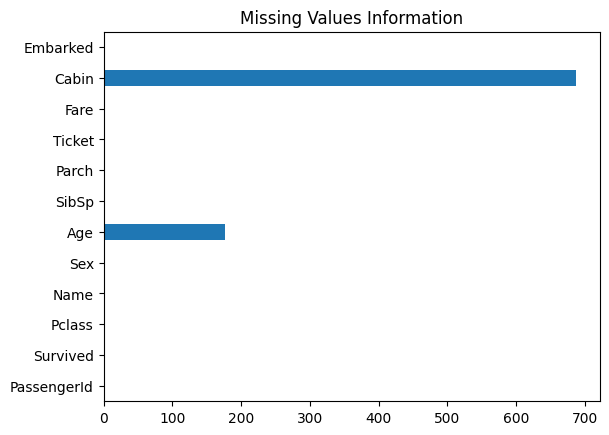

In [41]:
import matplotlib.pyplot as plt
#Check null values present in dataset
df.isnull().sum().plot(kind='barh')
plt.title('Missing Values Information')
plt.show()

In [42]:
#Drop duplicates records present in dataset
data=df.copy()  #Prepare copy of dataframe
data.drop_duplicates(inplace=True)

In [43]:
#Descriptive Stats:Numerical and Categorical Columns
#Segregate Numerical Columns and Categorical Columns
numerical_col=data.select_dtypes(exclude='object').columns
categprical_col=data.select_dtypes(include='object').columns
#----------------------------------------------------------------------------
from collections import OrderedDict
stats=[]
for i in numerical_col:
  numerical_stats=OrderedDict({
      'Feauture':i,
      'Count':data[i].count(),
      '% of Missing Values':(data[i].isnull().sum()/len(data))*100,
      'Maximum':data[i].max(),
      'Minimum':data[i].min(),
      'Mean':data[i].mean(),
      'Median':data[i].median(),
      'Q1':data[i].quantile(0.25),
      'Q2':data[i].quantile(0.50),
      'Q3':data[i].quantile(0.75),
      'IQR':data[i].quantile(0.75)-data[i].quantile(0.25),
      'Standard Deviation':data[i].std(),
      'Variance':data[i].var(),
      'Skewness':data[i].skew(),
      'Kurtosis':data[i].kurtosis()
  })

  stats.append(numerical_stats)
  numerical_stats=pd.DataFrame(stats)
numerical_stats

,Feauture,Count,% of Missing Values,Maximum,Minimum,Mean,Median,Q1,Q2,Q3,IQR,Standard Deviation,Variance,Skewness,Kurtosis
0,PassengerId,891,0.00000,891.0000,1.00,446.000000,446.0000,223.5000,446.0000,668.5,445.0000,257.353842,66231.000000,0.000000,-1.200000
1,Survived,891,0.00000,1.0000,0.00,0.383838,0.0000,0.0000,0.0000,1.0,1.0000,0.486592,0.236772,0.478523,-1.775005
2,Pclass,891,0.00000,3.0000,1.00,2.308642,3.0000,2.0000,3.0000,3.0,1.0000,0.836071,0.699015,-0.630548,-1.280015
3,Age,714,19.86532,80.0000,0.42,29.699118,28.0000,20.1250,28.0000,38.0,17.8750,14.526497,211.019125,0.389108,0.178274
4,SibSp,891,0.00000,8.0000,0.00,0.523008,0.0000,0.0000,0.0000,1.0,1.0000,1.102743,1.216043,3.695352,17.880420
5,Parch,891,0.00000,6.0000,0.00,0.381594,0.0000,0.0000,0.0000,0.0,0.0000,0.806057,0.649728,2.749117,9.778125
6,Fare,891,0.00000,512.3292,0.00,32.204208,14.4542,7.9104,14.4542,31.0,23.0896,49.693429,2469.436846,4.787317,33.398141


In [44]:
from collections import OrderedDict
stats1=[]
for i in categorical_col:
  categorical_stats=OrderedDict({
      'Feature':i,
      'Count':data[i].count(),
      '% of Missing Values':(data[i].isnull().sum()/len(data))*100,
      'Unique Values':data[i].nunique(),
      'Mode':data[i].mode()[0],
      'Value Counts':data[i].value_counts()
  })
  stats1.append(categorical_stats)
  categorical_stats=pd.DataFrame(stats1)
categorical_stats_report

,Feature,Count,% of Missing Values,Unique Values,Mode,Value Counts
0,Name,891,0.000000,891,"Abbing, Mr. Anthony","Name Dooley, Mr. Patrick ..."
1,Sex,891,0.000000,2,male,"Sex male 577 female 314 Name: count, d..."
2,Ticket,891,0.000000,681,1601,Ticket 347082 7 1601 ...
3,Cabin,204,77.104377,147,B96 B98,Cabin G6 4 C23 C25 C27 4 B96 B9...
4,Embarked,889,0.224467,3,S,Embarked S 644 C 168 Q 77 Name: coun...


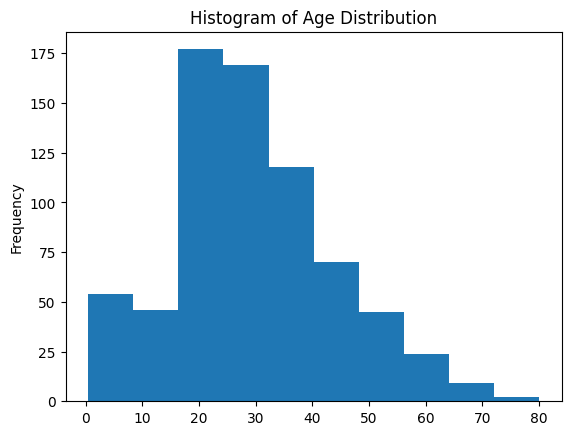

In [45]:
#Step 3:EDA Exploratory Data Analysis

#---------------------------------------
#Checking average age distribution
data['Age'].plot(kind='hist')
plt.title('Histogram of Age Distribution')
plt.show()

In [46]:
pd.crosstab(index =[data['Sex'],
                    data['Survived'],
                    data['Pclass']],
            columns=[data['Embarked']],
            margins=True)

Embarked                  C   Q    S  All
Sex    Survived Pclass                   
female 0        1         1   0    2    3
                2         0   0    6    6
                3         8   9   55   72
       1        1        42   1   46   89
                2         7   2   61   70
                3        15  24   33   72
male   0        1        25   1   51   77
                2         8   1   82   91
                3        33  36  231  300
       1        1        17   0   28   45
                2         2   0   15   17
                3        10   3   34   47
All                     168  77  644  889

In [47]:
pd.crosstab(index =[data['Sex'],
                    data['Survived'],
                    data['Pclass']],
            columns=[data['Embarked']],
            margins=True,
            normalize='all')*100

Embarked                        C         Q          S         All
Sex    Survived Pclass                                            
female 0        1        0.112486  0.000000   0.224972    0.337458
                2        0.000000  0.000000   0.674916    0.674916
                3        0.899888  1.012373   6.186727    8.098988
       1        1        4.724409  0.112486   5.174353   10.011249
                2        0.787402  0.224972   6.861642    7.874016
                3        1.687289  2.699663   3.712036    8.098988
male   0        1        2.812148  0.112486   5.736783    8.661417
                2        0.899888  0.112486   9.223847   10.236220
                3        3.712036  4.049494  25.984252   33.745782
       1        1        1.912261  0.000000   3.149606    5.061867
                2        0.224972  0.000000   1.687289    1.912261
                3        1.124859  0.337458   3.824522    5.286839
All                     18.897638  8.661417  72.440945  100.000000

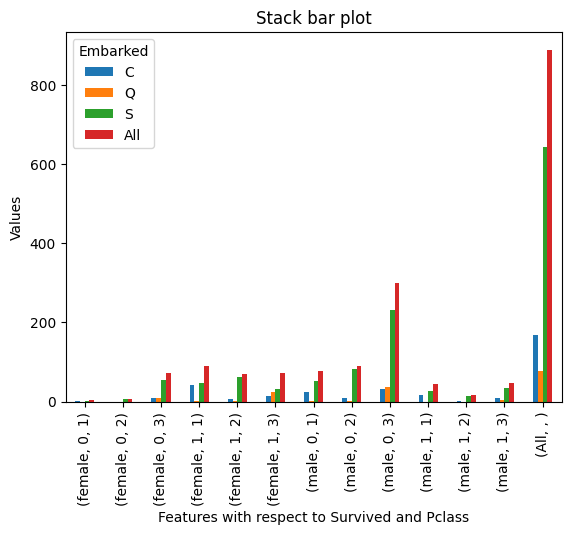

In [48]:
pd.crosstab(index =[data['Sex'],
                    data['Survived'],
                    data['Pclass']],
            columns=[data['Embarked']],
            margins=True.plot(kind='bar')
plt.title('Stack bar plot')
plt.xlabel('Features with respect to Survived and Pclass')
plt.ylabel('Values')
plt.show())

#*Parch column i.e. Parent and child, shows Q1=Q3 also skewness shows and kurtosis 9.77. Based on scenario we may drop the column.Since maximum people have no child with them.
#* The maximum age of people who boarded theie journey is between 20 to 30.
#* 18.89% people boarded their journey from Chelsburg(Out of 168 peopleX1 will be male and X2 will be female).Out of which X3 and X4 were survived.

In [49]:
#Prepare dataset for SouthHampton i.e. S
SouthHampton = data[data['Embarked']=='S']
SouthHampton.to_csv('SouthHampton.csv')

#Prepare datset for Queenstown i.e.Q
Queenstown = data[data['Embarked']=='Q']
Queenstown.to_csv('Queenstown.csv')

#Prepare datset for Cherbourg i.e.C
Chelsberg = data[data['Embarked']=='C']
Chelsberg.to_csv('Cherbourg.csv')


<Axes: >

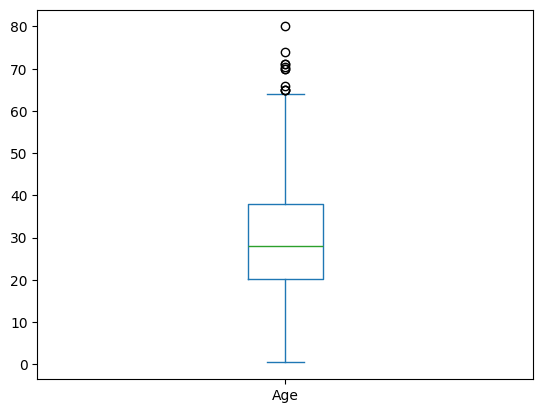

In [50]:
data['Age'].plot(kind='box')

<Axes: ylabel='Density'>

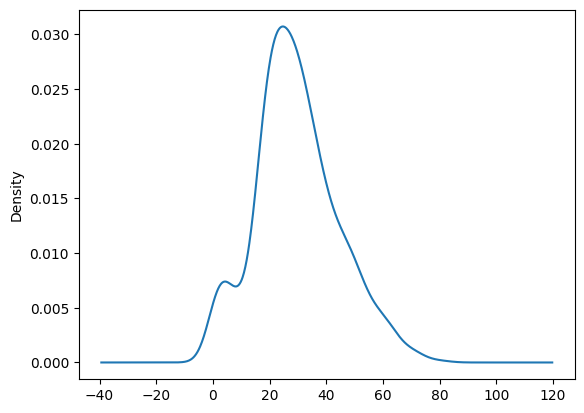

In [51]:
data['Age'].plot(kind='kde')

In [52]:
#Checking Outliers Present in Age Column
Q1=data['Age'].quantile(0.25)
Q3=data['Age'].quantile(0.75)
IQR=Q3-Q1
LW=Q1-1.5*IQR
UW=Q3+1.5*IQR
print(Q1,Q3,IQR,LW,UW)
print(IQR)

20.125 38.0 17.875 -6.6875 64.8125
17.875
